# Does a spiking output neuron cost you anything on rate-coded spike trains?

Two groups, one question: **is this digit a 3?**

| | Input | Input layer | Output layer | Decision |
|---|---|---|---|---|
| **Control** | EmbedMNIST, 84 static activations | dense `Linear(84, 1)` | *same layer* — real-valued | logit > 0 |
| **Experiment** | Po-MNIST, 84 spike channels x T frames | dense `Linear(84, 1)`, applied per frame — **not spiking** | single **LIF** neuron | spike count > T/2 |

In the Experiment arm there is no spiking hidden layer. The spike frames go straight into
an ordinary dense layer; that layer's real-valued output is injected as current into one
leaky integrate-and-fire neuron, whose spike count over `T` timesteps is the decision.

**EmbedMNIST** is the input to both arms: for each MNIST digit, the 84 post-ReLU
activations of the penultimate (`fc2`) layer of a LeNet-5 trained on MNIST. 60,000 train /
10,000 test vectors of length 84, labelled by digit. Values are non-negative (ReLU), about
half are exactly zero, and the observed maximum is 27.83.

**Po-MNIST is EmbedMNIST converted into a dataset using Bernoulli-style Poisson rate
encoding.** Each of the 84 activations is read as a firing rate in the range
**1–28 Hz** and turned into a `T`-step spike train (rate encoding, § 2). Same digits, same
84 features, same 84 input channels as the control — the only thing added is the stochastic
temporal encoding. This is what replaces N-MNIST, whose 34x34x2 = 2,312 channels made the
two arms unequal in both resolution and input width.

**Both arms use the same number of training and test samples** (`N_TRAIN` / `N_TEST`)
so that any accuracy difference is not just "one model saw 6x more data".

Because the spike trains are a lossy re-encoding of the very activations the control already
sees, the Experiment arm carries **no information the control lacks** — at best it ties.
Two things still differ at once: the encoding (exact activations → sampled spikes) and the
output neuron (real-valued → spiking), so a gap is attributable to the *pair*, not to the
LIF alone. What is no longer a confound is sensor and resolution. See the closing note for
what a third arm would buy you.

No energy modelling. Accuracy only.


## 1 · Setup

In [4]:
import sys, subprocess, os, time
def _pip(*a): subprocess.run([sys.executable, "-m", "pip", "install", "-q", *a], check=False)

try:
    import snntorch
except Exception:
    # Colab: install snntorch with --no-deps so pip cannot reshuffle the NumPy the running
    # kernel has already imported. tonic and torchvision are no longer required -- both arms
    # read EmbedMNIST.npz off Google Drive, and Po-MNIST is rate-encoded from those same
    # activations, so there is no dataset to download.
    _pip("--no-deps", "snntorch")

import numpy as np, torch, torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import snntorch as snn
from snntorch import surrogate

DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| snntorch", snn.__version__, "| device", DEV)


torch 2.11.0+cu128 | snntorch 1.0.0 | device cuda


## 1B · EmbedMNIST location — **EDIT THE CELL BELOW**

`EmbedMNIST.npz` is not downloaded by this notebook; it is read from your Google
Drive. Mount the Drive and put the full path to the file in `EMBEDMNIST_PATH`.

In Colab, the easiest way to get the exact path: open the file browser (folder icon,
left sidebar) → `drive/MyDrive/...` → right-click the file → **Copy path**.


In [6]:
# @title 1B · EmbedMNIST location   <<<  EDIT THIS CELL  >>>

# =============================================================================
# ==                                                                         ==
# ==   >>>>>   ENTER THE GOOGLE DRIVE PATH TO EmbedMNIST.npz HERE   <<<<<    ==
# ==                                                                         ==
# =============================================================================

EMBEDMNIST_PATH = "/content/drive/MyDrive/COSMOS_2026_Cluster_1/SNN_ANN_Compare/EmbedMNIST.npz"   # <-- CHANGE ME
MOUNT_DRIVE     = True   # set False if the .npz is already on the local Colab disk

# =============================================================================
# ==                    nothing below this line needs editing                 ==
# =============================================================================

if MOUNT_DRIVE:
    try:
        from google.colab import drive
        drive.mount("/content/drive")   # follow the auth prompt the first time
    except Exception as e:
        print("Drive not mounted (not in Colab, or already mounted):", e)

assert os.path.exists(EMBEDMNIST_PATH), (
    f"EmbedMNIST.npz not found at:\n    {EMBEDMNIST_PATH}\n"
    "Fix EMBEDMNIST_PATH above. Colab: file browser (folder icon) -> right-click the "
    "file -> 'Copy path'."
)

with np.load(EMBEDMNIST_PATH) as _d:
    print("EmbedMNIST OK ->", EMBEDMNIST_PATH)
    for _k in ("train_X", "train_y", "test_X", "test_y"):
        assert _k in _d, f"missing array '{_k}' in {EMBEDMNIST_PATH}"
        print(f"  {_k:<8s} {str(_d[_k].shape):<14s} {_d[_k].dtype}")
    assert _d["train_X"].shape[1] == 84, "expected 84-wide activation vectors"
    print(f"  activation range: {_d['train_X'].min():.3f} .. {_d['train_X'].max():.3f} "
          f"(train) | {(_d['train_X'] == 0).mean():.1%} exact zeros")


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
EmbedMNIST OK -> /content/drive/MyDrive/COSMOS_2026_Cluster_1/SNN_ANN_Compare/EmbedMNIST.npz
  train_X  (60000, 84)    float32
  train_y  (60000,)       int64
  test_X   (10000, 84)    float32
  test_y   (10000,)       int64
  activation range: 0.000 .. 27.827 (train) | 49.5% exact zeros


In [7]:
import random

CFG = dict(
    TARGET  = 3,       # the digit to detect
    T       = 30,      # timesteps / Po-MNIST Bernoulli spike frames
    T_WINDOW_FRACTION = 25/30, # Fraction (0-1) of the T timesteps the LIF neuron processes
    BETA    = 0.9,     # LIF membrane decay
    EPOCHS  = 8,
    LR      = 2e-3,
    BATCH   = 128,
    SEEDS   = [random.randint(1, 1000) for i in range(10)],
    N_TRAIN = 10000,   # SAME for both arms -- this is what makes the comparison fair
    N_TEST  = 2000,
    # ---- Po-MNIST rate encoding: EmbedMNIST activation -> firing rate in Hz ----
    RATE_MIN_HZ = 1.0,   # bottom of the nominal encoded range
    RATE_MAX_HZ = 28.0,  # top of the range; a unit at this rate spikes EVERY timestep
                         # (EmbedMNIST's observed max activation is 27.83)
    RATE_AFFINE = False, # False: rate_Hz = activation, clipped to RATE_MAX_HZ. A zero
                         #        activation is silent; RATE_MIN_HZ is descriptive only.
                         # True : rate_Hz = RATE_MIN + (activation/act_max)*(RATE_MAX-RATE_MIN),
                         #        so even a zero activation fires at RATE_MIN_HZ.
    RATE_GAIN   = 1.0,   # extra multiplier on the per-step spike probability
    ENCODE_SEED = 12345, # spike trains are drawn ONCE with this seed, then frozen as a dataset
    DATA_DIR= "./data",
)
# One timestep is defined as lasting 1 / RATE_MAX_HZ seconds, which is what makes
# "RATE_MAX_HZ" mean "one spike per timestep" (p = 1). The Hz axis is only meaningful
# relative to this dt.
CFG["DT_S"] = 1.0 / CFG["RATE_MAX_HZ"]
os.makedirs(CFG["DATA_DIR"], exist_ok=True)

def set_seed(s):
    np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)

print(CFG)
print(f"\n1 timestep = {CFG['DT_S'] * 1e3:.2f} ms  ->  T = {CFG['T']} steps "
      f"= {CFG['T'] * CFG['DT_S'] * 1e3:.0f} ms encoding window")
print(f"rate {CFG['RATE_MIN_HZ']:.0f}-{CFG['RATE_MAX_HZ']:.0f} Hz  ->  per-step spike "
      f"probability {CFG['RATE_MIN_HZ'] * CFG['DT_S']:.4f}-"
      f"{CFG['RATE_MAX_HZ'] * CFG['DT_S']:.4f}")


{'TARGET': 3, 'T': 30, 'T_WINDOW_FRACTION': 0.8333333333333334, 'BETA': 0.9, 'EPOCHS': 8, 'LR': 0.002, 'BATCH': 128, 'SEEDS': [366, 699, 506, 612, 795, 1000, 260, 522, 496, 274], 'N_TRAIN': 10000, 'N_TEST': 2000, 'RATE_MIN_HZ': 1.0, 'RATE_MAX_HZ': 28.0, 'RATE_AFFINE': False, 'RATE_GAIN': 1.0, 'ENCODE_SEED': 12345, 'DATA_DIR': './data', 'DT_S': 0.03571428571428571}

1 timestep = 35.71 ms  ->  T = 30 steps = 1071 ms encoding window
rate 1-28 Hz  ->  per-step spike probability 0.0357-1.0000


## 2 · Data

**EmbedMNIST** → 84 post-ReLU LeNet-5 `fc2` activations per digit, loaded from the `.npz`
on Drive, normalised with *training* statistics only, then subsampled to
`N_TRAIN` / `N_TEST`. This replaces the 784 raw pixels the earlier version of this notebook
used; nothing about the task or the models changes except input width (784 → 84).

**Po-MNIST** → the same EmbedMNIST activations, rate-encoded into spike trains. An
activation is read as a **firing rate in Hz, spanning 1–28 Hz**, and a unit firing at
`rate` Hz spikes independently at each timestep with probability `rate * DT_S`, where
`DT_S = 1 / RATE_MAX_HZ`. So its spike count over the window is
Binomial(`T`, `rate * DT_S`) — the discrete-time stand-in for a Bernoulli process of that
rate (Bernoulli rate-encoding used to approximate Poisson rate-encoding), and the rule
`snntorch`'s `spikegen.rate` uses. A unit at the 28 Hz ceiling fires every step; a unit at
1 Hz fires with probability 1/28 ≈ 0.036 per step. 84 channels per frame, matching the
control's input width exactly.

Three things to know about how it is built:

* **What "Hz" means here.** `T` is a step count, not wall-clock time, so a rate in Hz only
  becomes a probability once a timestep duration is fixed. `RATE_MAX_HZ` is *defined* as the
  rate that saturates the channel (p = 1), which pins `DT_S = 1/28 s ≈ 35.7 ms`. Change
  `RATE_MAX_HZ` and you change `DT_S` with it.
* **Zeros.** With `RATE_AFFINE = False` (default) the mapping is `rate_Hz = activation`, so
  the ~50% of activations that are exactly 0 encode as 0 Hz and stay silent — `RATE_MIN_HZ`
  labels the bottom of the useful range but is not a floor. Set `RATE_AFFINE = True` to
  instead map `[0, act_max] → [1, 28] Hz`, which makes dead units fire at 1 Hz.
* The spike trains are drawn **once**, under `ENCODE_SEED`, and cached. It is a fixed
  dataset, not fresh noise every epoch — redrawing per epoch would act as data augmentation
  and would no longer be the same comparison.
* Encoding reads **raw non-negative activations**, not the z-scored features the control arm
  is fed: a firing rate has to be non-negative. The control's normalisation is unchanged.

Both arms draw from the same memoised EmbedMNIST activation pool and are class-balanced to
`N_TRAIN` / `N_TEST` by `balance_data`.


In [8]:
from tqdm.auto import tqdm
import collections

def check(y, name):
    hist = collections.Counter(int(v) for v in y)
    print(f"  {name}: {len(y)} samples, distribution: {dict(sorted(hist.items()))}")

def balance_data(X, y, target_val, n_total):
    # Find indices for target and non-target
    is_target = (y == target_val)
    idx_target = np.where(is_target)[0]
    idx_other = np.where(~is_target)[0]

    # Determine how many of each we can take to keep it balanced
    # We aim for n_total/2 of each, but limited by available target samples
    n_each = min(len(idx_target), len(idx_other), n_total // 2)

    sel_target = np.random.permutation(idx_target)[:n_each]
    sel_other = np.random.permutation(idx_other)[:n_each]

    sel = np.concatenate([sel_target, sel_other])
    np.random.shuffle(sel)
    return X[sel], y[sel]

# ---------- EmbedMNIST ----------
_EMBED_ARRAYS = {}
def embed_arrays(train):
    # EmbedMNIST as float32 [N, 84] post-ReLU activations (>= 0), read once from the .npz on
    # Drive and reused by BOTH arms so the control and Po-MNIST draw from exactly the same
    # activation pool.
    if train not in _EMBED_ARRAYS:
        split = "train" if train else "test"
        with np.load(EMBEDMNIST_PATH) as d:
            X = np.ascontiguousarray(d[f"{split}_X"], dtype=np.float32)   # [N, 84]
            y = np.asarray(d[f"{split}_y"]).astype(np.int64)              # [N]
        _EMBED_ARRAYS[train] = (X, y)
    return _EMBED_ARRAYS[train]

def load_embed():
    # Load full dataset first to find target samples
    Xtr_all, ytr_all = embed_arrays(True)
    Xte_all, yte_all = embed_arrays(False)

    # Balance relative to CFG["N_TRAIN"] and CFG["N_TEST"]
    Xtr, ytr = balance_data(Xtr_all, ytr_all, CFG["TARGET"], CFG["N_TRAIN"])
    Xte, yte = balance_data(Xte_all, yte_all, CFG["TARGET"], CFG["N_TEST"])

    mu, sd = Xtr.mean(), Xtr.std()
    return (Xtr - mu) / (sd + 1e-6), ytr, (Xte - mu) / (sd + 1e-6), yte

# ---------- Po-MNIST (EmbedMNIST Poisson rate-encoded into spike trains using Bernoulli encoding) ----------
def act_to_rate_hz(Xact, act_max):
    """EmbedMNIST activation -> firing rate in Hz, within [0 or RATE_MIN_HZ, RATE_MAX_HZ].

    RATE_AFFINE = False (default): the activation IS the rate in Hz, clipped at
      RATE_MAX_HZ = 28 (chosen because EmbedMNIST's observed max activation is 27.83).
      An exact zero -> 0 Hz -> silent, so RATE_MIN_HZ only labels the bottom of the
      nominal range and is not enforced as a floor.
    RATE_AFFINE = True: [0, act_max] is mapped linearly onto [RATE_MIN_HZ, RATE_MAX_HZ], so
      even a zero activation fires at RATE_MIN_HZ.
    """
    lo, hi = CFG["RATE_MIN_HZ"], CFG["RATE_MAX_HZ"]
    if CFG["RATE_AFFINE"]:
        return lo + np.clip(Xact, 0.0, act_max) / max(act_max, 1e-12) * (hi - lo)
    return np.clip(Xact, 0.0, hi)

def rate_encode(Xact, T, rng, desc, act_max):
    """Activation -> firing rate (Hz) -> Bernoulli spike train.

    A unit firing at `rate` Hz spikes independently at each timestep with probability
    rate * DT_S * RATE_GAIN (clipped to [0, 1]), where DT_S = 1 / RATE_MAX_HZ. Its count
    over the window is therefore Binomial(T, rate * DT_S): the discrete-time stand-in for a
    Bernoulli (semi-Poisson) process of that rate. Same rule as snntorch's spikegen.rate --
    repeat, scale, clip, Bernoulli. Done in numpy, in chunks, to keep the temporary float
    array small.
    """
    dt, gain = CFG["DT_S"], CFG["RATE_GAIN"]
    N, C = Xact.shape
    out = np.zeros((N, T, C), dtype=np.uint8)
    for i in tqdm(range(0, N, 512), desc=desc):
        hz = act_to_rate_hz(Xact[i:i + 512], act_max)                                # [b, C] in Hz
        p  = np.clip(hz * dt * gain, 0.0, 1.0).astype(np.float32)[:, None, :]        # [b, 1, C]
        draws = rng.random((p.shape[0], T, C), dtype=np.float32)                     # [b, T, C]
        out[i:i + 512] = (draws < p).astype(np.uint8)
    return out

def load_pomnist():
    T, gain = CFG["T"], CFG["RATE_GAIN"]
    tag = f"{CFG['RATE_MIN_HZ']:g}-{CFG['RATE_MAX_HZ']:g}hz_aff{int(CFG['RATE_AFFINE'])}"
    cache = os.path.join(CFG["DATA_DIR"],
        f"pomnist_embed_balanced_{T}_{tag}_{gain}_{CFG['ENCODE_SEED']}_{CFG['N_TRAIN']}_{CFG['N_TEST']}.pt")
    if os.path.exists(cache):
        d = torch.load(cache, weights_only=False); print("  [cache hit]", d["src"])
        return d["Xtr"], d["ytr"], d["Xte"], d["yte"], d["src"]

    # Raw non-negative activations here, NOT the z-scored features the control gets: the
    # value is being used as a firing rate.
    Xtr_all, ytr_all = embed_arrays(True)
    Xte_all, yte_all = embed_arrays(False)

    Xtr_act, ytr = balance_data(Xtr_all, ytr_all, CFG["TARGET"], CFG["N_TRAIN"])
    Xte_act, yte = balance_data(Xte_all, yte_all, CFG["TARGET"], CFG["N_TEST"])

    act_max = float(Xtr_all.max())   # training-split statistic only (27.83 for EmbedMNIST)

    # Drawn once and frozen, so Po-MNIST is a dataset rather than per-epoch augmentation.
    rng = np.random.default_rng(CFG["ENCODE_SEED"])
    Xtr = rate_encode(Xtr_act, T, rng, "Po-MNIST train", act_max)
    Xte = rate_encode(Xte_act, T, rng, "Po-MNIST test", act_max)
    src = (f"Po-MNIST (Bernoulli rate-encoded EmbedMNIST, "
           f"{CFG['RATE_MIN_HZ']:g}-{CFG['RATE_MAX_HZ']:g} Hz"
           f"{', affine' if CFG['RATE_AFFINE'] else ''}, gain {gain}, balanced)")
    print(f"  encoding range: activation 0 -> {act_to_rate_hz(np.zeros((1, 1), dtype=np.float32), act_max).item():.2f} Hz"
          f" | activation {act_max:.2f} -> {act_to_rate_hz(np.array([[act_max]], dtype=np.float32), act_max).item():.2f} Hz")
    print(f"  encoded {len(Xtr)}+{len(Xte)} samples -> {Xtr.shape[1]} frames x {Xtr.shape[2]} "
          f"channels | mean rate {Xtr.mean():.4f} spikes/unit/step "
          f"(= {Xtr.mean() / CFG['DT_S']:.2f} Hz mean firing rate)")

    torch.save(dict(Xtr=Xtr, ytr=ytr, Xte=Xte, yte=yte, src=src), cache)
    return Xtr, ytr, Xte, yte, src

print("EmbedMNIST"); A_tr, a_ytr, A_te, a_yte = load_embed()
check(a_ytr, "EmbedMNIST train"); check(a_yte, "EmbedMNIST test")

print("Po-MNIST"); E_tr, e_ytr, E_te, e_yte, SRC = load_pomnist()
check(e_ytr, "Po-MNIST train"); check(e_yte, "Po-MNIST test")
assert E_tr.shape[-1] == A_tr.shape[-1] == 84, "both arms must be 84 channels wide (EmbedMNIST width)"

b = lambda y: (y == CFG["TARGET"]).astype(np.float32)
a_ytr, a_yte, e_ytr, e_yte = b(a_ytr), b(a_yte), b(e_ytr), b(e_yte)
print(f"\ntask: is the digit a {CFG['TARGET']}?")
print(f"  control    test positive rate {a_yte.mean():.4f}")
print(f"  experiment test positive rate {e_yte.mean():.4f}")


EmbedMNIST
  EmbedMNIST train: 10000 samples, distribution: {0: 550, 1: 642, 2: 550, 3: 5000, 4: 564, 5: 479, 6: 558, 7: 570, 8: 514, 9: 573}
  EmbedMNIST test: 2000 samples, distribution: {0: 119, 1: 121, 2: 104, 3: 1000, 4: 113, 5: 94, 6: 102, 7: 120, 8: 115, 9: 112}
Po-MNIST


Po-MNIST train:   0%|          | 0/20 [00:00<?, ?it/s]

Po-MNIST test:   0%|          | 0/4 [00:00<?, ?it/s]

  encoding range: activation 0 -> 0.00 Hz | activation 27.83 -> 27.83 Hz
  encoded 10000+2000 samples -> 30 frames x 84 channels | mean rate 0.0917 spikes/unit/step (= 2.57 Hz mean firing rate)
  Po-MNIST train: 10000 samples, distribution: {0: 551, 1: 627, 2: 573, 3: 5000, 4: 520, 5: 482, 6: 536, 7: 590, 8: 567, 9: 554}
  Po-MNIST test: 2000 samples, distribution: {0: 105, 1: 127, 2: 97, 3: 1000, 4: 98, 5: 110, 6: 115, 7: 117, 8: 109, 9: 122}

task: is the digit a 3?
  control    test positive rate 0.5000
  experiment test positive rate 0.5000


## 3 · The two models

**Control (ANN).** `Linear(84, 1)`. This is logistic regression: one weight per EmbedMNIST
activation, one bias, one real number out. Nothing spikes anywhere.

**Experiment (spikes → dense → LIF).** `Linear(84, 1)` is an ordinary dense layer — it
takes the 0/1 spike frame for one timestep and produces a real-valued current. **It is
not a spiking layer.** That current is fed into one `snn.Leaky` LIF neuron, which at each
of the `T` timesteps does

```
mem[t]   = beta * mem[t-1] + current[t] - spike[t-1] * threshold
spike[t] = 1 if mem[t] > threshold else 0
```

and the prediction is whether it fired more than `T/2` times. The hard threshold isn't
differentiable, so `snn.Leaky` uses a surrogate gradient on the backward pass; the dense
layer learns whatever currents push the spike count to the right side of `T/2`.

With Po-MNIST both arms are now **parameter-matched**: 84 weights + 1 bias = 85 parameters
each. Under N-MNIST the experiment arm had 2,313 parameters against the control's 785, which
was a third difference between the arms on top of input and output neuron.


In [9]:
SG = surrogate.fast_sigmoid()

class ControlANN(nn.Module):
    # 84 static EmbedMNIST activations -> 1 real-valued logit. Non-spiking end to end.
    def __init__(self, n_in):
        super().__init__(); self.fc = nn.Linear(n_in, 1)
    def forward(self, x):                      # x: [B, 84]
        return self.fc(x).squeeze(1)

class EventLIF(nn.Module):
    # Po-MNIST spike frames -> ordinary dense layer (per frame) -> ONE LIF output neuron.
    # n_in is 84 (EmbedMNIST width), taken from the data, so it matches the control exactly.
    def __init__(self, n_in):
        super().__init__()
        self.fc  = nn.Linear(n_in, 1)          # NOT spiking -- a plain dense layer
        self.lif = snn.Leaky(beta=CFG["BETA"], spike_grad=SG)
        self.AC_Counter = 0
        self._last_batch_size = 1

    def forward(self, x):                      # x: [B, T, 84]
        B = x.shape[0]
        num_timesteps_to_process = int(CFG['T'] * CFG['T_WINDOW_FRACTION'])
        mem = self.lif.init_leaky(); count = 0

        # 1. Total spikes in this batch across all channels and time
        # Only count spikes within the processed window
        total_batch_spikes = int(x[:, :num_timesteps_to_process].sum().item())

        for t in range(num_timesteps_to_process):
            # 2. Neuron update
            spk, mem = self.lif(self.fc(x[:, t]), mem)
            count = count + spk

        # Store the average ACs per single sample (inference)
        self.AC_Counter = total_batch_spikes / B

        return count.squeeze(1)

print("Model updated: 84-wide input (EmbedMNIST / Po-MNIST); "
      "AC_Counter = average input spikes per inference (Total/B).")


Model updated: 84-wide input (EmbedMNIST / Po-MNIST); AC_Counter = average input spikes per inference (Total/B).


## 4 · Metrics and training harness

Only ~10% of digits are 3s, so plain accuracy is close to worthless — always saying "no"
scores ~0.90. Every result below therefore reports **balanced accuracy** (always-say-no
scores 0.50), precision, recall, F1, and the raw confusion matrix, **per seed with a
standard deviation**, so you can see whether a difference is bigger than run-to-run noise.

The positive class is up-weighted in the loss (`pos_weight`) so the model is not simply
rewarded for ignoring it.

In [10]:
def metrics(pred, true):
    tp = float(((pred==1)&(true==1)).sum()); fp = float(((pred==1)&(true==0)).sum())
    fn = float(((pred==0)&(true==1)).sum()); tn = float(((pred==0)&(true==0)).sum())
    rec  = tp/max(tp+fn,1e-9); spec = tn/max(tn+fp,1e-9); prec = tp/max(tp+fp,1e-9)
    return dict(acc=(tp+tn)/len(true), bal_acc=0.5*(rec+spec), precision=prec, recall=rec,
                f1=2*prec*rec/max(prec+rec,1e-9), tp=int(tp), fp=int(fp), fn=int(fn), tn=int(tn))

def train_eval(Model, Xtr, ytr, Xte, yte, spiking, seed):
    set_seed(seed)
    model = Model(Xtr.shape[-1]).to(DEV)
    pos   = float(ytr.mean())
    lossf = nn.BCEWithLogitsLoss(pos_weight=torch.tensor((1-pos)/pos).to(DEV))
    opt   = torch.optim.Adam(model.parameters(), lr=CFG["LR"])
    # keep X in its native dtype (uint8 for events); cast per batch on the device
    mk = lambda X, y, bs, sh: DataLoader(
        TensorDataset(torch.from_numpy(np.ascontiguousarray(X)), torch.from_numpy(y).float()),
        batch_size=bs, shuffle=sh)
    tr, te = mk(Xtr, ytr, CFG["BATCH"], True), mk(Xte, yte, 256, False)

    num_timesteps_to_process = int(CFG['T'] * CFG['T_WINDOW_FRACTION'])
    thr = num_timesteps_to_process/2 if spiking else 0.0

    for _ in range(CFG["EPOCHS"]):
        model.train()
        for xb, yb in tr:
            # Ensure only the relevant portion of timesteps is passed if the model expects it.
            # For EventLIF, the forward method handles the slicing based on T_WINDOW_FRACTION.
            xb, yb = xb.to(DEV).float(), yb.to(DEV)
            opt.zero_grad(); lossf(model(xb) - thr, yb).backward(); opt.step()
    model.eval(); P, Y = [], []
    with torch.no_grad():
        for xb, yb in te:
            P.append((model(xb.to(DEV).float()).cpu() > thr).float()); Y.append(yb)
    return metrics(torch.cat(P).numpy(), torch.cat(Y).numpy()), model # RETURN THE MODEL

def report(name, runs, base):
    print(f"\n{name}   ({len(runs)} seeds)")
    # Removed bal_acc as requested for balanced datasets
    for k in ["acc", "precision", "recall", "f1"]:
        v = np.array([r[k] for r in runs])
        print(f"  {k:<10s} {v.mean():.4f} +/- {v.std(ddof=1):.4f}   per-seed {np.round(v,4).tolist()}")
    print(f"  always-say-NO:  acc {base:.4f}")
    for s, r in zip(CFG["SEEDS"], runs):
        print(f"  seed {s}:  TP {r['tp']:5d}  FP {r['fp']:5d}  FN {r['fn']:5d}  TN {r['tn']:5d}")
    return {k: float(np.mean([r[k] for r in runs])) for k in ["acc","bal_acc","precision","recall","f1"]}

print("harness ready")


harness ready


## 5 · (1C) Control Group — ANN on EmbedMNIST


In [11]:

t0 = time.time()
# train_eval returns (metrics, model); keep the metrics dicts for report()
ctrl_results = [train_eval(ControlANN, A_tr, a_ytr, A_te, a_yte, spiking=False, seed=s)
                for s in CFG["SEEDS"]]
ctrl = [res[0] for res in ctrl_results]
Ctrl = report("CONTROL   EmbedMNIST 84 -> 1 (no spiking)", ctrl, 1 - a_yte.mean())
print(f"  [{time.time()-t0:.0f}s]")



CONTROL   EmbedMNIST 84 -> 1 (no spiking)   (10 seeds)
  acc        0.9944 +/- 0.0006   per-seed [0.9955, 0.995, 0.9935, 0.9945, 0.994, 0.995, 0.994, 0.9945, 0.994, 0.9945]
  precision  0.9972 +/- 0.0008   per-seed [0.998, 0.997, 0.996, 0.998, 0.997, 0.998, 0.997, 0.998, 0.996, 0.997]
  recall     0.9917 +/- 0.0008   per-seed [0.993, 0.993, 0.991, 0.991, 0.991, 0.992, 0.991, 0.991, 0.992, 0.992]
  f1         0.9944 +/- 0.0006   per-seed [0.9955, 0.995, 0.9935, 0.9945, 0.994, 0.995, 0.994, 0.9945, 0.994, 0.9945]
  always-say-NO:  acc 0.5000
  seed 366:  TP   993  FP     2  FN     7  TN   998
  seed 699:  TP   993  FP     3  FN     7  TN   997
  seed 506:  TP   991  FP     4  FN     9  TN   996
  seed 612:  TP   991  FP     2  FN     9  TN   998
  seed 795:  TP   991  FP     3  FN     9  TN   997
  seed 1000:  TP   992  FP     2  FN     8  TN   998
  seed 260:  TP   991  FP     3  FN     9  TN   997
  seed 522:  TP   991  FP     2  FN     9  TN   998
  seed 496:  TP   992  FP     4  FN 

## 6 · (1E) Experimental Group — SNN on Po-MNIST spike trains → LIF output neuron


In [12]:
t0 = time.time()
expt_results = [train_eval(EventLIF, E_tr, e_ytr, E_te, e_yte, spiking=True, seed=s)
                for s in CFG["SEEDS"]]

expt = [res[0] for res in expt_results] # Extract metrics
trained_models = [res[1] for res in expt_results] # Extract trained models

# We'll use the model from the first seed for our visualization
trained_eventlif_model = trained_models[0]

Expt = report(f"EXPERIMENT   {SRC}: 84 -> dense -> 1 LIF", expt, 1 - e_yte.mean())
print(f"  [{time.time()-t0:.0f}s]")




EXPERIMENT   Po-MNIST (Bernoulli rate-encoded EmbedMNIST, 1-28 Hz, gain 1.0, balanced): 84 -> dense -> 1 LIF   (10 seeds)
  acc        0.9818 +/- 0.0023   per-seed [0.9835, 0.984, 0.984, 0.9795, 0.982, 0.979, 0.9835, 0.98, 0.9835, 0.9785]
  precision  0.9873 +/- 0.0031   per-seed [0.9909, 0.9909, 0.9909, 0.9839, 0.9839, 0.9848, 0.9889, 0.9858, 0.9889, 0.9838]
  recall     0.9761 +/- 0.0023   per-seed [0.976, 0.977, 0.977, 0.975, 0.98, 0.973, 0.978, 0.974, 0.978, 0.973]
  f1         0.9816 +/- 0.0023   per-seed [0.9834, 0.9839, 0.9839, 0.9794, 0.982, 0.9789, 0.9834, 0.9799, 0.9834, 0.9784]
  always-say-NO:  acc 0.5000
  seed 366:  TP   976  FP     9  FN    24  TN   991
  seed 699:  TP   977  FP     9  FN    23  TN   991
  seed 506:  TP   977  FP     9  FN    23  TN   991
  seed 612:  TP   975  FP    16  FN    25  TN   984
  seed 795:  TP   980  FP    16  FN    20  TN   984
  seed 1000:  TP   973  FP    15  FN    27  TN   985
  seed 260:  TP   978  FP    11  FN    22  TN   989
  seed 52

## 7 · Side by side

In [13]:
print(f"spike data source: {SRC}\n")
print(f"{'metric':<12s}{'control (ANN)':>18s}{'experiment (LIF)':>20s}{'difference':>14s}")
for k in ["acc", "bal_acc", "precision", "recall", "f1"]:
    c = np.array([r[k] for r in ctrl]); e = np.array([r[k] for r in expt])
    print(f"{k:<12s}{c.mean():>11.4f} +-{c.std(ddof=1):<5.4f}{e.mean():>13.4f} +-{e.std(ddof=1):<6.4f}{e.mean()-c.mean():>+14.4f}")

gap  = Ctrl["bal_acc"] - Expt["bal_acc"]
pool = np.sqrt(np.var([r["bal_acc"] for r in ctrl], ddof=1) +
               np.var([r["bal_acc"] for r in expt], ddof=1))
print(f"\nbalanced-accuracy gap = {gap:+.4f}   (pooled seed sd {pool:.4f} -> {abs(gap)/max(pool,1e-9):.1f}x)")
print("both arms: same N_TRAIN, same N_TEST, same 84 inputs, same epochs, same LR, same seeds.")
print(f"time window used: {CFG['T_WINDOW_FRACTION']}")


spike data source: Po-MNIST (Bernoulli rate-encoded EmbedMNIST, 1-28 Hz, gain 1.0, balanced)

metric           control (ANN)    experiment (LIF)    difference
acc              0.9944 +-0.0006       0.9818 +-0.0023       -0.0127
bal_acc          0.9944 +-0.0006       0.9818 +-0.0023       -0.0127
precision        0.9972 +-0.0008       0.9873 +-0.0031       -0.0099
recall           0.9917 +-0.0008       0.9761 +-0.0023       -0.0156
f1               0.9944 +-0.0006       0.9816 +-0.0023       -0.0128

balanced-accuracy gap = +0.0127   (pooled seed sd 0.0023 -> 5.5x)
both arms: same N_TRAIN, same N_TEST, same 84 inputs, same epochs, same LR, same seeds.
time window used: 0.8333333333333334


In [292]:
# @title 8 · 1C vs 1E Compute
# =============================================================================
# Per-inference compute for both arms, memory-inclusive model
# (Efficiency_Math_Explained_v2 §4.4):   Energy = MACs·22.6 + ACs·16.33 + leaks·11.8
#
# Both arms are 84 wide with one output unit, so N_syn and N_neur match exactly.
# That is what makes the break-even threshold valid here (§6.4 Condition C) --
# it was NOT valid in the earlier 784-vs-2312 version of this comparison.
#
# Operation counts below are MEASURED. Energies are MODELLED. Kept separate.
# =============================================================================

E_MAC_SYN, E_AC_SYN, E_LEAK = 22.6, 16.33, 11.8      # §10 quick reference

# ---- topology, identical in both arms ---------------------------------------
n_in   = A_tr.shape[-1]        # 84 EmbedMNIST activations
n_out  = 1                     # one output unit
N_SYN  = n_in * n_out          # 84 synapses
N_NEUR = 1                     # ONE LIF neuron in 1E; 1C has no membrane at all

# T_eff must be computed EXACTLY as EventLIF.forward computes it -- int() truncation
# included. With T=30 and T_WINDOW_FRACTION=0.04, T*fraction is 1.2 but only int(1.2)=1
# timestep is ever simulated. Charging the leak for 1.2 timesteps bills 20% of a
# timestep that never ran.
T_EFF = int(CFG['T'] * CFG['T_WINDOW_FRACTION'])

# ---- 1C control: real-valued input, ONE pass, every synapse a MAC -----------
# EmbedMNIST activations are ordinary numbers, so every synapse costs a MAC (§3.3).
# ControlANN.forward calls fc once: there is no time axis, so no T-tax (§9, trap 6).
ctrl_macs   = N_SYN * 1
ctrl_acs    = 0                                  # a pure ANN must have ZERO ACs (§5)
ctrl_leak   = 0                                  # no spiking neuron -> no membrane
ctrl_energy = ctrl_macs * E_MAC_SYN

# ---- 1E experiment: measure ACs across the WHOLE test set, not one sample ---
# AC_Counter depends only on x.sum(), never on the weights, so an untrained model
# gives identical counts to a trained one. Accumulate RAW totals and divide once at
# the end: dividing per batch would weight a short final batch equally with a full
# one and distort the average (§7.3 is the same class of normalisation bug).
model_test = EventLIF(n_in).to(DEV)
raw_spikes, n_seen = 0.0, 0
with torch.no_grad():
    for i in range(0, len(E_te), 256):
        xb = torch.from_numpy(E_te[i:i + 256]).float().to(DEV)
        _ = model_test(xb)
        raw_spikes += model_test.AC_Counter * xb.shape[0]   # undo forward's /B
        n_seen     += xb.shape[0]
spikes_per_inf = raw_spikes / n_seen

# independent cross-check: same quantity straight off the array, no model involved
_direct = float(E_te[:, :T_EFF].sum(dtype=np.float64)) / len(E_te)
assert abs(spikes_per_inf - _direct) < 1e-6, "AC measurement disagrees with the raw data"

# One input spike drives every synapse fanning out of its channel -> n_out AC ops.
# n_out is 1 here, so ACs == spikes; the multiply is written out so the rule stays
# correct if the output layer is ever widened.
expt_macs   = 0                                  # spike-driven input -> no MACs at all
expt_acs    = spikes_per_inf * n_out
expt_leak   = N_NEUR * T_EFF                     # membrane update, paid spike or not
expt_energy = expt_acs * E_AC_SYN + expt_leak * E_LEAK

# ---- break-even (§6.4). The control makes ONE pass, so there is NO T multiplier;
# using T x 1.38 against a single-pass ANN is trap 6 and would inflate the SNN's
# budget by a factor of T. The leak sits inside the threshold, scaled by T_eff.
threshold   = (E_MAC_SYN - N_NEUR * T_EFF * E_LEAK / N_SYN) / E_AC_SYN
spk_per_syn = expt_acs / N_SYN                   # §7: total ACs / total synapses

# ---- report -----------------------------------------------------------------
print(f"spike data source: {SRC}")
print(f"topology (both arms)  N_syn {N_SYN}   N_neur {N_NEUR}   "
      f"T_eff {T_EFF} of {CFG['T']} timesteps  (T_WINDOW_FRACTION = {CFG['T_WINDOW_FRACTION']})")
print(f"ACs averaged over all {n_seen:,} test samples\n")

print(f"{'':<22}{'MACs':>10}{'ACs':>10}{'leak':>8}{'energy (norm)':>16}")
print("-" * 66)
print(f"{'1C  control (ANN)':<22}{ctrl_macs:>10,.0f}{ctrl_acs:>10,.1f}"
      f"{ctrl_leak:>8,}{ctrl_energy:>16,.1f}")
print(f"{'1E  experiment (LIF)':<22}{expt_macs:>10,.0f}{expt_acs:>10,.1f}"
      f"{expt_leak:>8,}{expt_energy:>16,.1f}")
print("-" * 66)

if expt_energy < ctrl_energy:
    print(f"1E is {ctrl_energy / expt_energy:.2f}x CHEAPER than 1C")
else:
    print(f"1E is {expt_energy / ctrl_energy:.2f}x MORE EXPENSIVE than 1C")

print(f"\nspikes/synapse   {spk_per_syn:.4f}")
print(f"break-even       {threshold:.4f}   (single-pass control, leak-corrected)")
print(f"budget used      {100 * spk_per_syn / threshold:.1f}%")

# The threshold and the energy comparison are separate routes to the same verdict.
# If they ever disagree, one of the two is wrong -- so check rather than assume.
assert (spk_per_syn < threshold) == (expt_energy < ctrl_energy), \
    "break-even and direct energy comparison disagree -- accounting is inconsistent"
print("\nCONSISTENT: break-even test and direct energy comparison agree")
print("Counts are measured; energies are modelled. Quote ratios, not absolute units.")


spike data source: Po-MNIST (Bernoulli rate-encoded EmbedMNIST, 1-28 Hz, gain 1.0, balanced)
topology (both arms)  N_syn 84   N_neur 1   T_eff 1 of 30 timesteps  (T_WINDOW_FRACTION = 0.03333333333333333)
ACs averaged over all 2,000 test samples

                            MACs       ACs    leak   energy (norm)
------------------------------------------------------------------
1C  control (ANN)             84       0.0       0         1,898.4
1E  experiment (LIF)           0       7.8       1           138.9
------------------------------------------------------------------
1E is 13.67x CHEAPER than 1C

spikes/synapse   0.0926
break-even       1.3754   (single-pass control, leak-corrected)
budget used      6.7%

CONSISTENT: break-even test and direct energy comparison agree
Counts are measured; energies are modelled. Quote ratios, not absolute units.


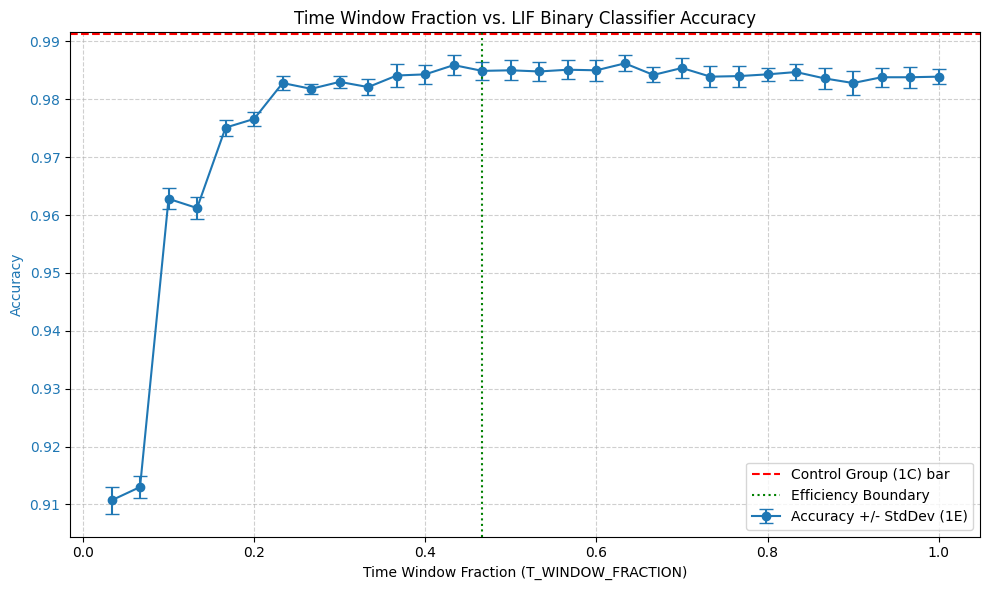

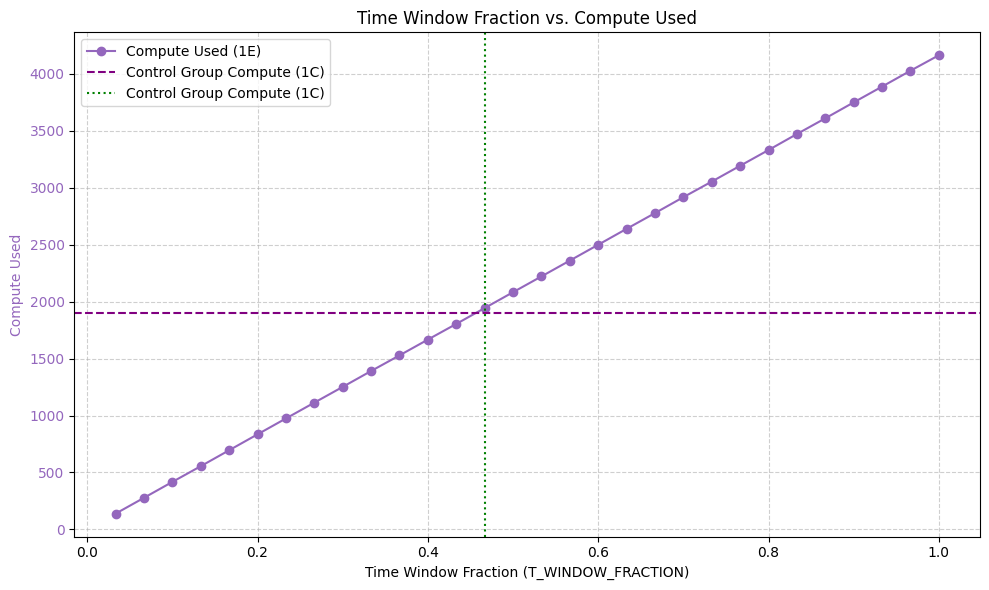

In [311]:
# @title 9 · Plotting Accuracy vs Time Window Fraction (Set 1)
import matplotlib.pyplot as plt

# They are stale twice over -- first for 784-channel Bern-MNIST, and now again for
# 84-channel Po-MNIST built from EmbedMNIST. Re-run the sweep and replace them before
# reading anything into this curve.
timewindowfraction = [(30 - i)/30 for i in range(30)]
accuracy =         [0.9839, 0.9838, 0.9838, 0.9828, 0.9836, 0.9847, 0.9843, 0.9840, 0.9839, 0.9854, 0.9842, 0.9862, 0.9850, 0.9851, 0.9848,
                    0.9850, 0.9849, 0.9859, 0.9843, 0.9841, 0.9821, 0.9830, 0.9818, 0.9828, 0.9766, 0.9751, 0.9612, 0.9628, 0.9130, 0.9107]
plus_minus_error = [0.0013, 0.0018, 0.0016, 0.0020, 0.0018, 0.0014, 0.0011, 0.0018, 0.0018, 0.0018, 0.0013, 0.0014, 0.0018, 0.0016, 0.0017,
                    0.0017, 0.0015, 0.0017, 0.0017, 0.0020, 0.0014, 0.0011, 0.0009, 0.0012, 0.0012, 0.0014, 0.0019, 0.0018, 0.0019, 0.0023]

compute_used =     [4160.3, 4024.5, 3885.2, 3746.7, 3607.0, 3469.1, 3328.8, 3190.6, 3052.0, 2915.1, 2775.5, 2637.4, 2497.8, 2358.7, 2219.9,
                    2081.5, 1942.3, 1803.2, 1665.8, 1527.2, 1390.1, 1250.8, 1112.6, 973.90, 834.60, 695.10, 555.20, 417.30, 277.8, 138.90]

fig, ax = plt.subplots(figsize=(10, 6))

# Plotting Accuracy vs Time Window Fraction
color = 'tab:blue'
ax.set_xlabel('Time Window Fraction (T_WINDOW_FRACTION)')
ax.set_ylabel('Accuracy', color=color)
ax.errorbar(timewindowfraction, accuracy, yerr=plus_minus_error, fmt='o-', color=color, capsize=5, label='Accuracy +/- StdDev (1E)')
ax.tick_params(axis='y', labelcolor=color)
ax.grid(True, linestyle='--', alpha=0.6)

# Add horizontal line
ax.axhline(y=0.9912, color='red', linestyle='--', label='Control Group (1C) bar')
# Add vertical line
ax.axvline(x=14/30, color='green', linestyle=':', label='Efficiency Boundary')

# Add legend
ax.legend()

plt.title('Time Window Fraction vs. LIF Binary Classifier Accuracy')
fig.tight_layout()
plt.show()

# New plot: Compute Used vs Time Window Fraction
fig2, ax2 = plt.subplots(figsize=(10, 6))
color2 = 'tab:purple'
ax2.set_xlabel('Time Window Fraction (T_WINDOW_FRACTION)')
ax2.set_ylabel('Compute Used', color=color2)
ax2.plot(timewindowfraction, compute_used, 'o-', color=color2, label='Compute Used (1E)')
ax2.tick_params(axis='y', labelcolor=color2)
ax2.grid(True, linestyle='--', alpha=0.6)

# Add horizontal line for control group compute
ax2.axhline(y=1898.4, color='purple', linestyle='--', label='Control Group Compute (1C)')
ax2.axvline(x=14/30, color='green', linestyle=':', label='Control Group Compute (1C)')

ax2.legend()
plt.title('Time Window Fraction vs. Compute Used')
fig2.tight_layout()
plt.show()

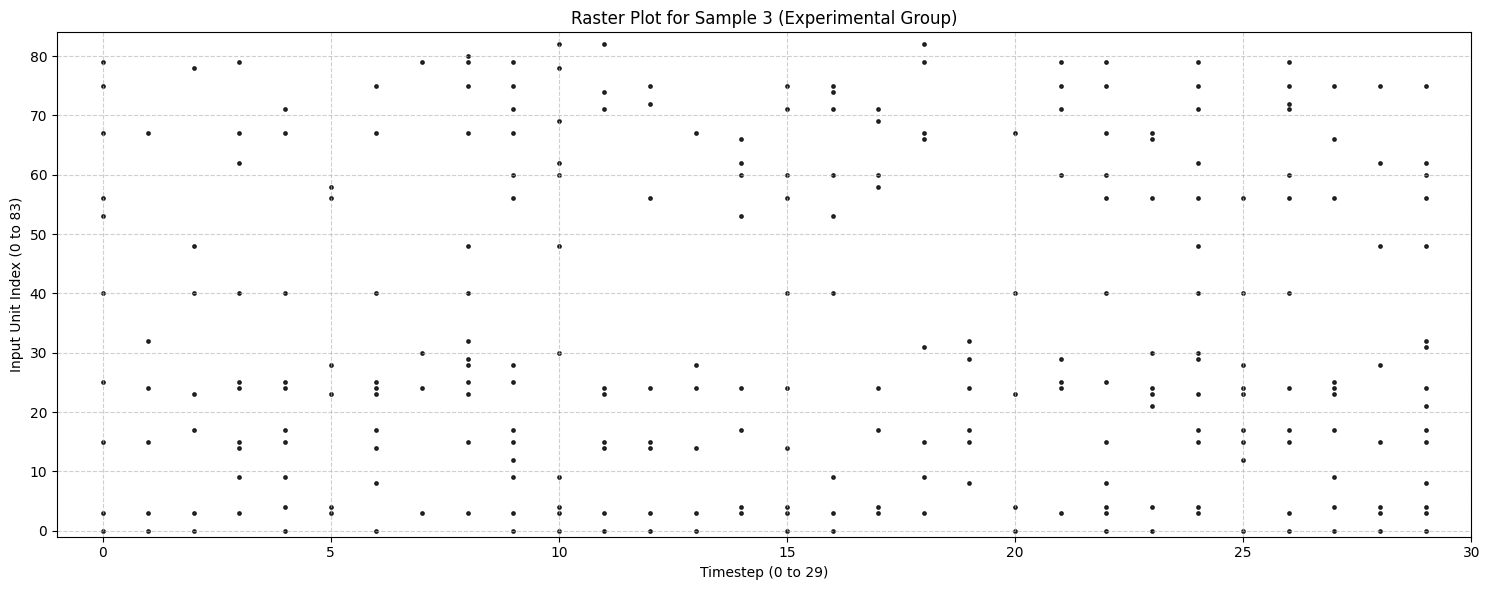

In [20]:
# @title Raster Plot for Samples
import matplotlib.pyplot as plt

# Select one sample from the experimental training data
# E_tr has shape [N_TRAIN, T, 84]
sample_index = 3 # You can change this to view a different sample
one_sample_spike_train = E_tr[sample_index]
n_channels = E_tr.shape[-1]   # 84

# The spike train for one sample is of shape [T, 84]
# We need to find the (timestep, neuron_index) pairs where spikes occur
spiking_timesteps, spiking_neurons = np.where(one_sample_spike_train == 1)

fig, ax = plt.subplots(figsize=(15, 6))
ax.scatter(spiking_timesteps, spiking_neurons, s=6, color='black', alpha=0.8)

ax.set_title(f'Raster Plot for Sample {sample_index} (Experimental Group)')
ax.set_xlabel(f'Timestep (0 to {CFG["T"]-1})')
ax.set_ylabel(f'Input Unit Index (0 to {n_channels-1})')
ax.set_xlim(-1, CFG['T'])
ax.set_ylim(-1, n_channels)
ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()


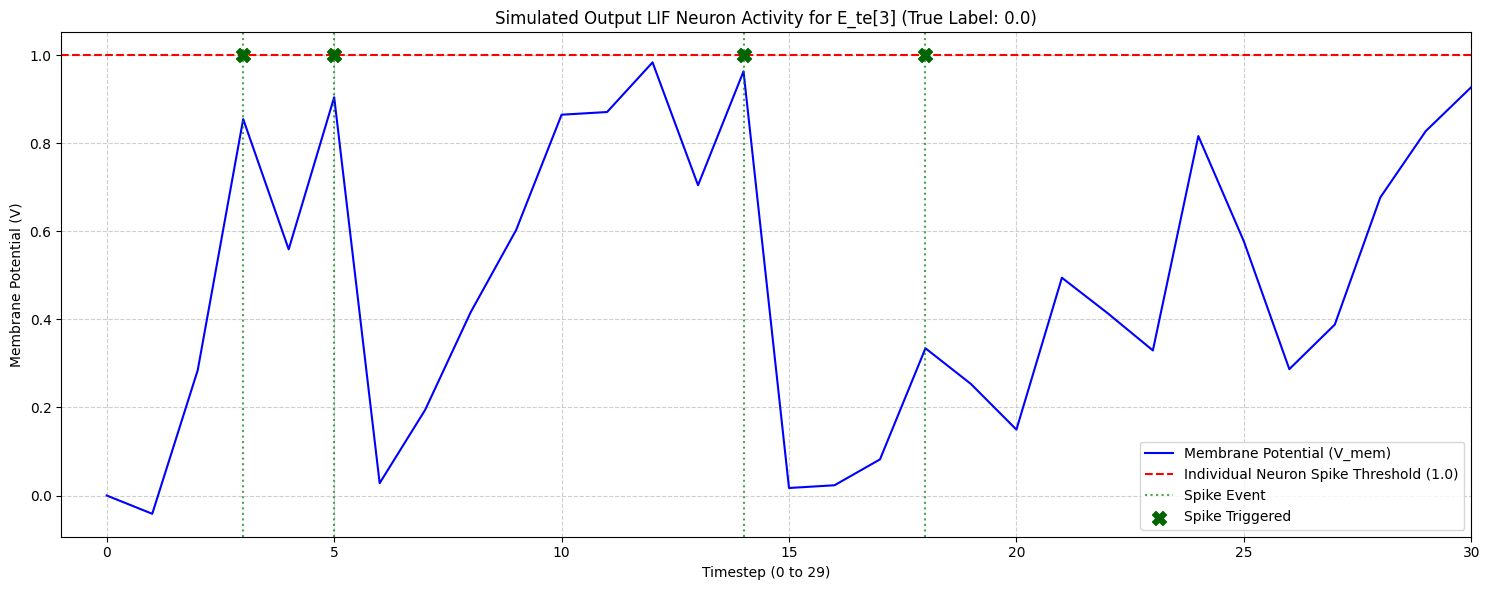

For E_te[3] (true label: 0.0):
  Total spikes generated in 30 timesteps: 4
  Total spikes in classification window (25 timesteps): 4
  Classifier decision threshold: 12.5


In [21]:
# @title LIF Activity Plot per Sample
import matplotlib.pyplot as plt
import torch
import numpy as np
import snntorch as snn
from snntorch import surrogate

# We'll use the already loaded 'trained_eventlif_model'
# from the training run for seed 0.

# Parameters for LIF simulation from CFG
beta = CFG['BETA']
T = CFG['T']
threshold_lif = 1.0 # Default threshold for snntorch.Leaky (individual neuron spike threshold)

# Select the test sample chosen in the raster-plot cell above
sample_index_te = sample_index
one_sample_spike_train_te = E_te[sample_index_te] # This is a numpy array of shape [T, 84]

# Convert the numpy spike train to a PyTorch tensor, float, and move to device
sample_input_tensor_te = torch.from_numpy(one_sample_spike_train_te).float().to(DEV)

# Simulate LIF neuron activity for E_te[9]
mem_te = 0.0 # Initial membrane potential at t=0
membrane_potentials_te = [mem_te] # Store V(0)
spike_times_te = []

with torch.no_grad(): # No need for gradients for this visualization
    for t in range(T):
        # Calculate input current for the current timestep's spike frame
        # sample_input_tensor_te[t] is [84]
        # Unsqueeze(0) to add batch dimension (1, 84) for the linear layer
        input_current_te = trained_eventlif_model.fc(sample_input_tensor_te[t].unsqueeze(0)).squeeze().item()

        # Update membrane potential: decay + integrate
        mem_te = beta * mem_te + input_current_te

        # Check for spike and apply reset if threshold is crossed
        if mem_te >= threshold_lif:
            spike_times_te.append(t) # Record spike at current timestep 't'
            mem_te -= threshold_lif      # Reset by subtraction

        membrane_potentials_te.append(mem_te) # Store V(t+1) after processing 't' (and resetting if spiked)

# Plotting
fig_te, ax_te = plt.subplots(figsize=(15, 6))

# Plot membrane potential over time (x-axis: 0 to T)
ax_te.plot(range(T + 1), membrane_potentials_te, label='Membrane Potential (V_mem)', color='blue')

# Plot individual neuron spike threshold line
ax_te.axhline(y=threshold_lif, color='red', linestyle='--', label=f'Individual Neuron Spike Threshold ({threshold_lif})')

# Mark spike events with vertical lines
for spike_t_te in spike_times_te:
    ax_te.axvline(x=spike_t_te, color='green', linestyle=':', alpha=0.7,
               label='Spike Event' if spike_t_te == spike_times_te[0] else '') # Label only once for legend
    # Add a scatter point at the threshold to clearly show the spike
    ax_te.scatter(spike_t_te, threshold_lif, color='darkgreen', marker='X', s=100, zorder=5, label='_nolegend_' if spike_t_te != spike_times_te[0] else 'Spike Triggered')

ax_te.set_title(f'Simulated Output LIF Neuron Activity for E_te[{sample_index_te}] (True Label: {e_yte[sample_index_te]})')
ax_te.set_xlabel(f'Timestep (0 to {T-1})')
ax_te.set_ylabel('Membrane Potential (V)')
ax_te.set_xlim(-1, T)
ax_te.grid(True, linestyle='--', alpha=0.6)
ax_te.legend()
plt.tight_layout()
plt.show()

num_timesteps_to_process = int(CFG['T'] * CFG['T_WINDOW_FRACTION'])
classifier_spike_threshold = num_timesteps_to_process / 2

print(f"For E_te[{sample_index_te}] (true label: {e_yte[sample_index_te]}):")
print(f"  Total spikes generated in {T} timesteps: {len(spike_times_te)}")
print(f"  Total spikes in classification window ({num_timesteps_to_process} timesteps): {len([s for s in spike_times_te if s < num_timesteps_to_process])}")
print(f"  Classifier decision threshold: {classifier_spike_threshold}")